In [35]:
from visualize import Embedding

embedding_baseline = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/',
        features_path='train.features.npy',
        targets_path='410.train.targets.npy',
        yaml_path="410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096_metadata.yaml",
        faiss_path='410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096'
    )
embedding_dispersion = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/',
        features_path='582.train.features.npy',
        targets_path='582.train.targets.npy',
        yaml_path="582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml",
        faiss_path='582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096'
    )
embedding_baseline.load_raw()
embedding_dispersion.load_raw()

embedding_baseline.load_faiss()
embedding_dispersion.load_faiss()

Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, nclusters=4096, nprobe=32, ntotal=21507934)
Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, features_model='/ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt', nclusters=2048, nprobe=32, ntotal=21507934)


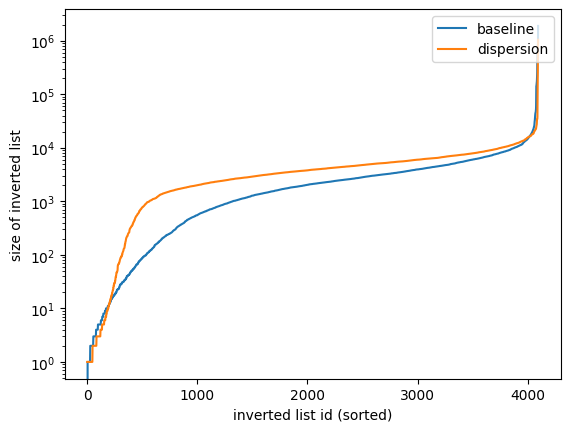

In [36]:
def get_imbalance_histogram(knn_index):
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))
    return sizes

sizes_baseline = get_imbalance_histogram(embedding_baseline.knn_index)
sizes_dispersion = get_imbalance_histogram(embedding_dispersion.knn_index)


def make_sizes_plot(sizes_baseline, sizes_dispersion):
    import matplotlib.pyplot as plt
    import numpy as np
    # sortщ
    sizes_baseline = np.sort(sizes_baseline)
    sizes_dispersion = np.sort(sizes_dispersion)

    fig, ax = plt.subplots()
    plt.plot(sizes_baseline, label='baseline')
    plt.plot(sizes_dispersion, label='dispersion')
    ax.legend(loc='upper right')
    ax.set_ylabel('size of inverted list')
    ax.set_xlabel('inverted list id (sorted)')
    # log scale
    ax.set_yscale('log')
    plt.show()

make_sizes_plot(sizes_baseline, sizes_dispersion)



In [40]:
import faiss, numpy as np, collections, math

# def _sample_rows(x, n=200_000, seed=123):
#     """Return a random subsample of rows (without copying when not needed)."""
#     if len(x) <= n:
#         return x
#     rng = np.random.default_rng(seed)
#     idx = rng.choice(len(x), n, replace=False)
#     return x[idx]

def _codes_from_index(index, vecs):
    """
    Return only the PQ part of `sa_encode` so that
    - shape == (n, index.code_size)
    - can be fed to pq.decode and for histograms
    """
    vecs = np.ascontiguousarray(vecs.astype(np.float32))
    full = index.sa_encode(vecs)                 # (n, header+code)
    pq_bytes = index.code_size                  # bytes that belong to PQ
    return full[:, -pq_bytes:]                  # drop header



def analyse_pq_layer(index: faiss.IndexIVFPQ,   # coarse index
                     train_vectors: np.ndarray,
                     sample_size: int = 100000):
    """
    Inspect PQ code utilisation and reconstruction quality on a sample of
    `train_vectors` (assumed original, **pre‑quantised** vectors).
    Returns a dict of useful metrics and histograms.
    """
    pq       = index.pq
    M, ksub  = pq.M, pq.ksub                   # e.g. 8 × 256 codewords
    codes = _codes_from_index(index, train_vectors)

    # ---- 1. codeword frequency per sub‑quantizer --------------------------
    hist = np.zeros((M, ksub), dtype=np.int64)
    for m in range(M):
        hist[m] = np.bincount(codes[:, m], minlength=ksub)

    dead_codewords = (hist == 0).sum()
    frac_dead      = dead_codewords / (M * ksub)

    # entropy per sub‑quantizer
    eps   = 1e-12
    probs = hist / hist.sum(axis=1, keepdims=True).clip(min=1)   # avoid /0
    ent   = -(probs * np.log2(probs + eps)).sum(axis=1)          # shape (M,)
    entropy_mean = float(ent.mean())
    entropy_min  = float(ent.min())

    # ---- 2. reconstruction error (RMSE) -----------------------------------
    recon = pq.decode(codes)                       # (n, d)
    err   = train_vectors[:len(codes)] - recon
    rmse  = float(np.sqrt((err**2).sum(1).mean()))

    # ---- 3. variance captured per sub‑space -------------------------------
    # For each sub‑vector dim, measure variance of the codebook centroids
    centroids = faiss.vector_to_array(pq.centroids)\
                  .reshape(ksub, M, -1)            # (ksub, M, d/M)
    var_per_M = centroids.var(axis=(0, 2))         # shape (M,)
    var_ratio = float(var_per_M.max() / var_per_M.min().clip(min=1e-9))

    return dict(
        M                 = M,
        ksub              = ksub,
        code_size_B       = index.code_size,
        sample_size       = int(len(codes)),
        dead_codewords    = int(dead_codewords),
        frac_dead         = round(frac_dead, 4),
        entropy_mean_bits = round(entropy_mean, 3),
        entropy_min_bits  = round(entropy_min, 3),
        rmse_L2           = round(rmse, 4),
        var_ratio_M_max_min = round(var_ratio, 3),
        hist_per_M        = hist,      # full histogram if you want to plot it
    )




In [41]:
stats_baseline = analyse_pq_layer(embedding_baseline.knn_index, embedding_baseline.keys[:100000])
stats_baseline

{'M': 64,
 'ksub': 256,
 'code_size_B': 64,
 'sample_size': 100000,
 'dead_codewords': 0,
 'frac_dead': 0.0,
 'entropy_mean_bits': 6.505,
 'entropy_min_bits': 6.327,
 'rmse_L2': 19.6338,
 'var_ratio_M_max_min': 3.051,
 'hist_per_M': array([[  160,   132,    36, ...,  2520,   919,  2941],
        [   58,   148,    88, ...,  1650, 12215,  1211],
        [  222,    87,    12, ...,   466, 15233,  2235],
        ...,
        [  136,    79,    56, ...,  1387, 14556,  4232],
        [  398,   111,    51, ...,   922, 14977,  1040],
        [  342,    57,   121, ...,  5920, 15579,  1312]])}

In [42]:
stats_dispersion = analyse_pq_layer(embedding_dispersion.knn_index, embedding_baseline.keys[:100000])
stats_dispersion

{'M': 64,
 'ksub': 256,
 'code_size_B': 64,
 'sample_size': 100000,
 'dead_codewords': 5,
 'frac_dead': 0.0003,
 'entropy_mean_bits': 6.309,
 'entropy_min_bits': 4.307,
 'rmse_L2': 19.007,
 'var_ratio_M_max_min': 4.442,
 'hist_per_M': array([[ 261,  226,   99, ...,  170,  280,  314],
        [ 402,   50,  147, ...,  881,  312,  496],
        [ 127,  172,   11, ...,   80,  386, 2740],
        ...,
        [ 126,  109,  155, ...,   81, 4129,  212],
        [ 382,   65,   52, ...,  145, 2336, 1145],
        [  98,   32,  242, ...,  154,  281,  111]])}

In [ ]:
from math import log2
log2(256)  # ideal entropy

8.0

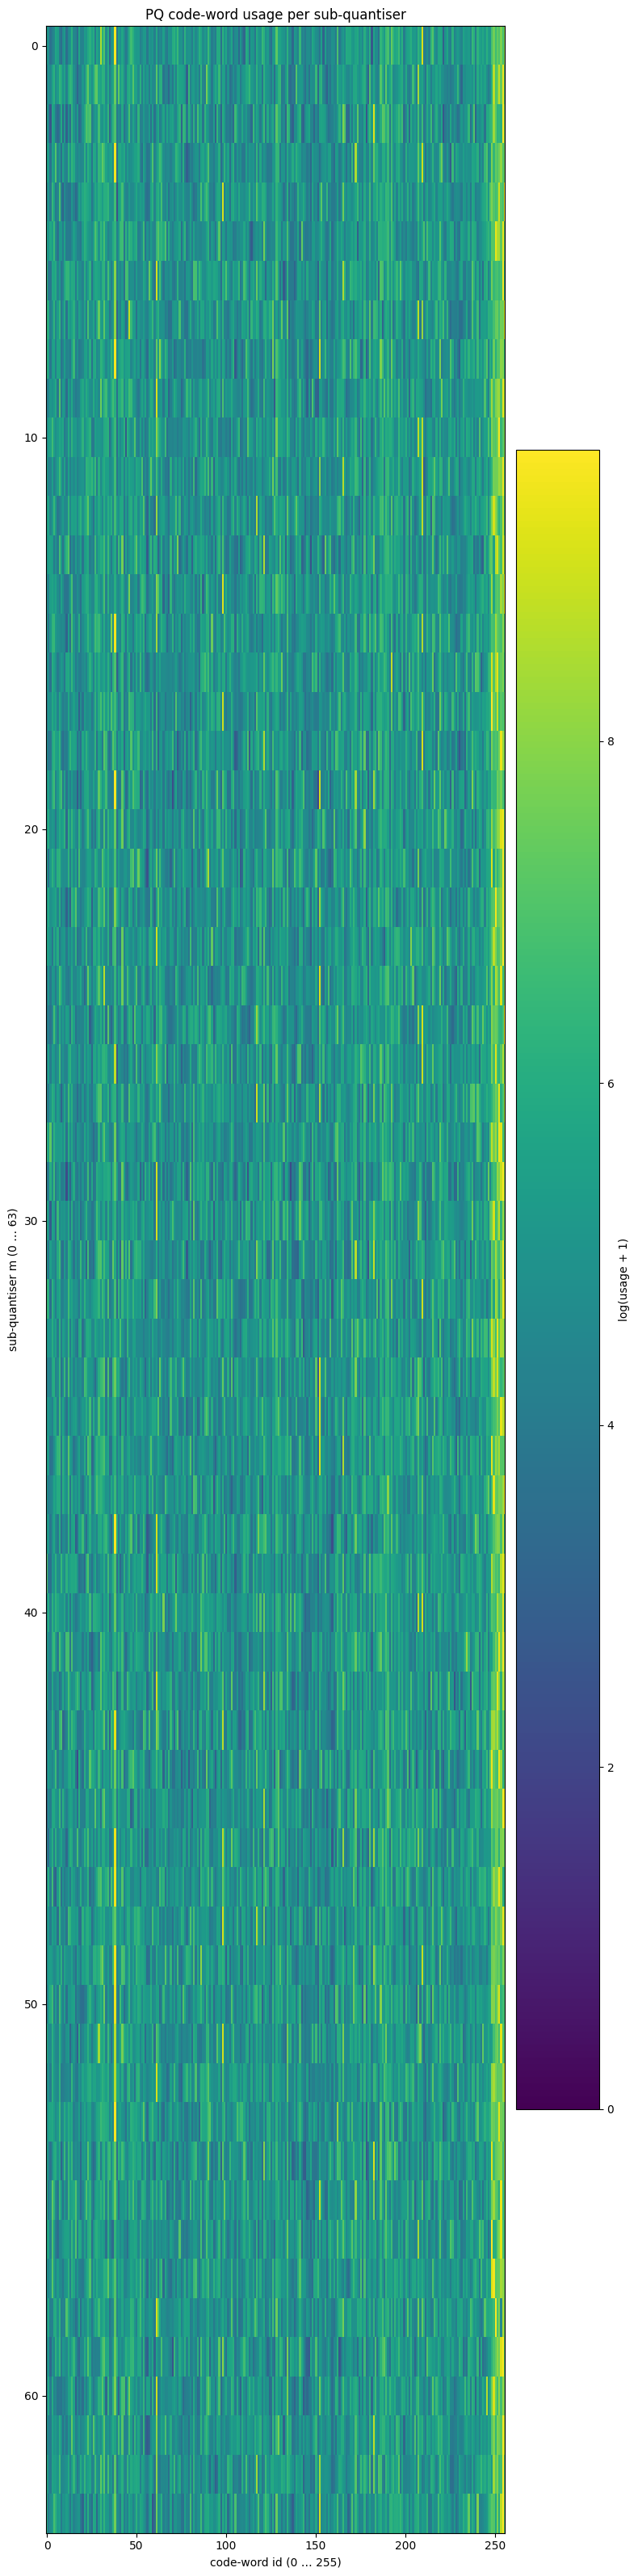

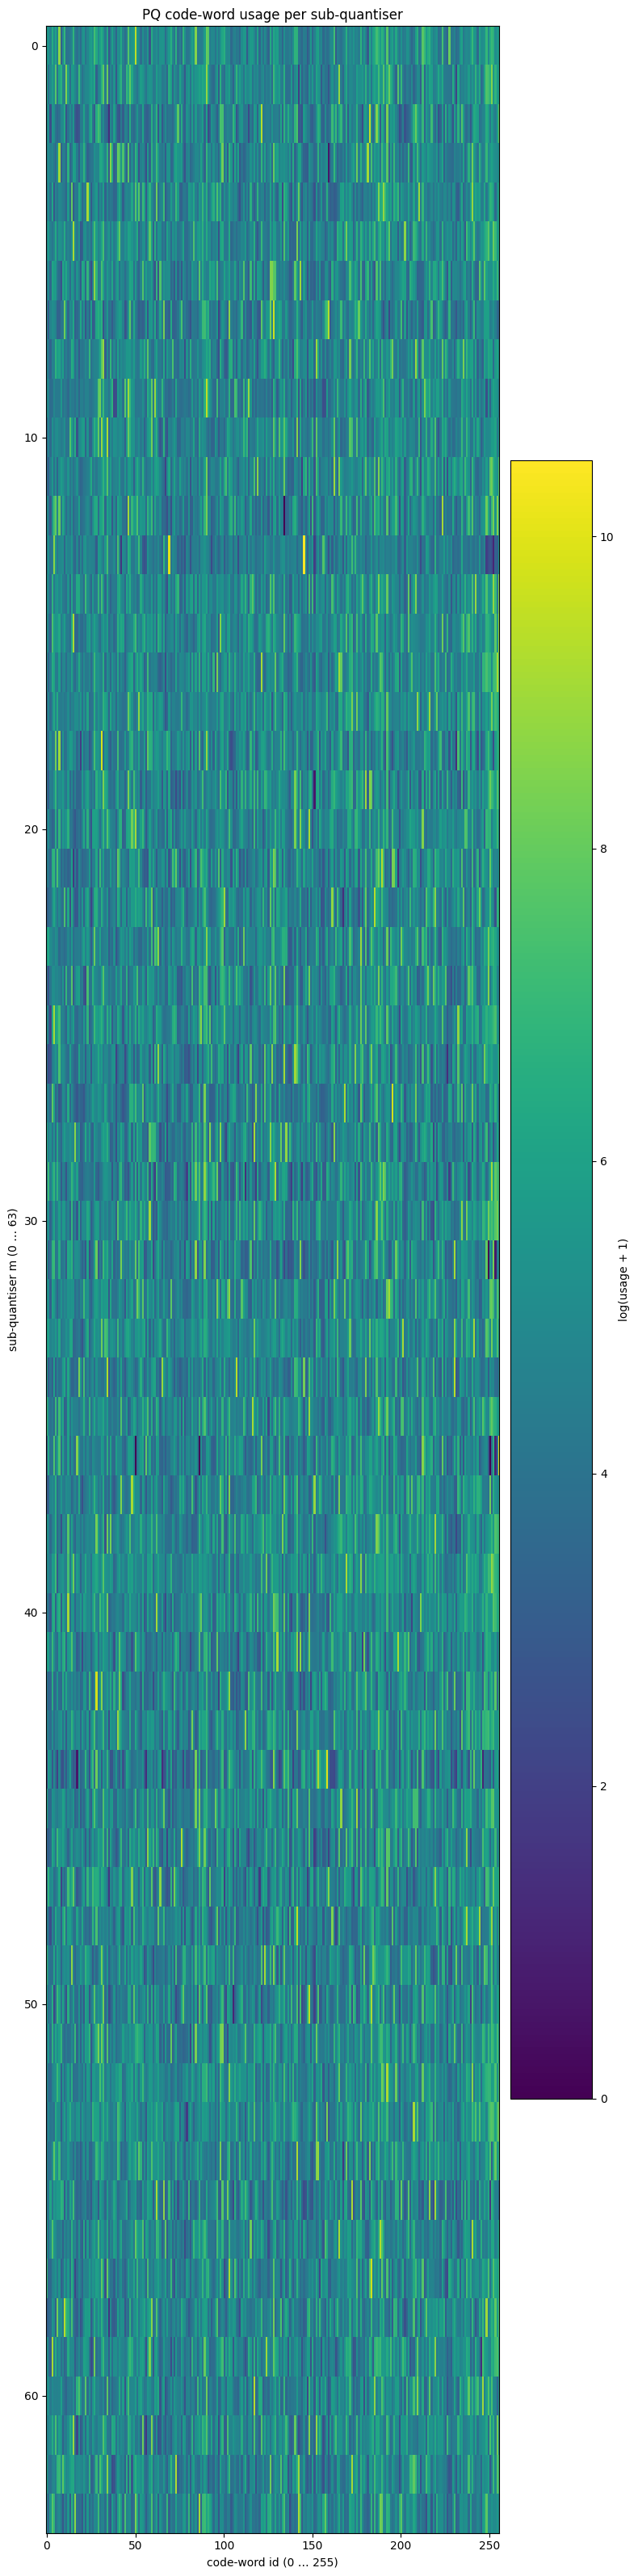

In [31]:
# plot histograms hist_per_M
from pathlib import Path
from typing import Optional
import matplotlib.pyplot as plt
import numpy as np

"""
'hist_per_M': array([[ 261,  226,   99, ...,  170,  280,  314],
        [ 402,   50,  147, ...,  881,  312,  496],
        [ 127,  172,   11, ...,   80,  386, 2740],
        ...,
        [ 126,  109,  155, ...,   81, 4129,  212],
        [ 382,   65,   52, ...,  145, 2336, 1145],
        [  98,   32,  242, ...,  154,  281,  111]])}
"""

def plot_pq_usage(
    hist_per_M: np.ndarray,
    *,
    log_scale: bool = True,
    cmap: str = "viridis",
    save_path = None,
) -> None:
    """
    Visualise FAISS PQ code‑word usage as a heat‑map.

    Parameters
    ----------
    hist_per_M : ndarray, shape (M, ksub)
        Usage counts.  Row m = sub‑quantiser index, column j = code‑word id.
    log_scale   : bool, default True
        If True, colour‑map is log(usage+1); otherwise linear counts.
    cmap        : str, matplotlib colour‑map to use.
    save_path   : str or Path or None
        If given, save the figure to this path (PNG/SVG/etc. inferred from
        extension).  The plot is still shown unless you suppress it with plt.close().
    """
    if hist_per_M.ndim != 2:
        raise ValueError(f"hist_per_M must be 2‑D, got shape {hist_per_M.shape}")

    # transform for colour scale
    data = np.log1p(hist_per_M) if log_scale else hist_per_M
    vmax = data.max()

    M, ksub = hist_per_M.shape
    width_in  = max(8, ksub * 0.03)   # heuristic so labels stay readable
    height_in = max(3, M * 0.5)

    plt.figure(figsize=(width_in, height_in))
    im = plt.imshow(
        data,
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
        interpolation="nearest",
    )
    cbar = plt.colorbar(im, pad=0.02)
    cbar.set_label("log(usage + 1)" if log_scale else "usage count")

    plt.xlabel(f"code‑word id (0 … {ksub - 1})")
    plt.ylabel(f"sub‑quantiser m (0 … {M - 1})")
    plt.title("PQ code‑word usage per sub‑quantiser")
    plt.tight_layout()

    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=200)
        print(f"Figure saved to {save_path}")

    plt.show()

plot_pq_usage(stats_baseline['hist_per_M'], log_scale=True, cmap='viridis')
plot_pq_usage(stats_dispersion['hist_per_M'], log_scale=True, cmap='viridis')